## 六方ZrO 不同参数优化方法 5个轨道

In [1]:
import numpy as np
import mindspore as ms
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt


from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

import numpy as np
import mindspore as ms
from mindquantum import *
import matplotlib.pyplot as plt
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer

In [2]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(1083064:124948245233664,MainProcess):2025-06-12-16:32:35.189.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [4]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 六方相ZrO

## LSTM优化

In [5]:
ZrO2d=get_mol(3)

[['Zr', [0.0, 0.0, 0.0]], ['O', [0.0, 3.0657299293969125, 0.8]]]
Hexagonal ZrO - Hartree-Fock energy: -575.9385060022055 Hartree.
Hexagonal ZrO - CCSD energy: -576.1026903963094 Hartree.


In [6]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [7]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
ansatz = ansatz_circuit   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit.as_encoder()       # 将初始化线路与拟设线路组合成总的线路
circ.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                            
╭───────────────────────┬────────────────────────────────────────────╮
│ Info                  │ value                                      │
├───────────────────────┼────────────────────────────────────────────┤
│ Number of qubit       │ 10                                         │
├───────────────────────┼────────────────────────────────────────────┤
│ Total number of gate  │ 6588                                       │
│ Barrier               │ 1440                                       │
│ Noise Channel         │ 0                                          │
│ Measurement           │ 0                                          │
├───────────────────────┼────────────────────────────────────────────┤
│ Parameter gate        │ 360                                        │
│ 27 encoder parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰───────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [8]:
# 采用一个 LSTM 作为对量子线路参数的经典优化器
# LSTM 输入为量子线路旧的参数，输出作为量子线路新的参数。
class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=len(circ.params_name),
                                            hidden_size=len(circ.params_name),
                                            num_layers=1,
                                            has_bias=True,
                                            batch_first=False,
                                            bidirectional=False)
        self.hidden_size = self.lstm.hidden_size
        self.batch_size = 1
        self.num_layers = 1
        self.hx = (Parameter(initializer( 'normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='h'),
                         Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='c'))

    def construct(self, x):
        _, (x, _) = self.lstm(x, self.hx)
        return x

In [9]:
# LSTM 层的损失函数为量子线路最终的期望值。
class All_Net(nn.Cell):
    def __init__(self, grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(grad_ops) # 量子线路的参数不直接参与训练
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):  # x 为量子线路旧的网络参数， out 为量子线路新的参数
        self.init_paras = self.lstm(self.init_paras)
        x = self.squeeze(self.init_paras)
        out = self.qnn_ops(x)
        return out

In [10]:
sim = Simulator('mqvector', circ.n_qubits) # 创建模拟器
grad_ops = sim.get_expectation_with_grad(ham, circ)

In [13]:

paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [14]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -575.3892
Step 10: Energy = -575.9307
Step 20: Energy = -575.9381
Step 30: Energy = -575.9389
Step 40: Energy = -575.9397
Step 50: Energy = -575.9405
Step 60: Energy = -575.9414
Step 70: Energy = -575.9418
Step 80: Energy = -575.9417
Step 90: Energy = -575.9419


/tmp/ipykernel_1083064/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


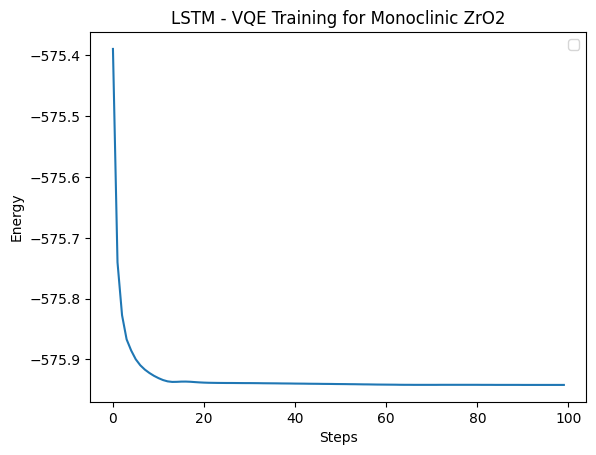

Estimated ground state energy of Monoclinic ZrO2: -575.94189453125


In [15]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [19]:
 -575.9418334960938

-575.9418334960938

In [20]:
print('L5_LSTM=',energy_data)

L5_LSTM= [-575.20465, -575.66437, -575.64923, -575.7836, -575.8701, -575.8882, -575.8969, -575.90784, -575.91754, -575.92474, -575.92975, -575.93304, -575.9351, -575.9364, -575.9372, -575.9376, -575.9379, -575.93805, -575.9382, -575.93823, -575.9383, -575.93835, -575.9385, -575.93854, -575.93866, -575.9388, -575.93884, -575.93896, -575.9391, -575.93915, -575.9393, -575.93933, -575.9394, -575.93945, -575.9395, -575.9396, -575.93964, -575.9397, -575.9397, -575.93976, -575.9398, -575.9398, -575.9399, -575.9399, -575.93994, -575.94, -575.94, -575.94006, -575.94006, -575.9401, -575.9401, -575.9402, -575.94025, -575.9403, -575.9403, -575.94037, -575.9404, -575.9405, -575.94055, -575.9406, -575.9407, -575.94073, -575.94086, -575.9409, -575.941, -575.94104, -575.94116, -575.9412, -575.9413, -575.9414, -575.94147, -575.9415, -575.9416, -575.94165, -575.9417, -575.9417, -575.9418, -575.9418, -575.9418, -575.9418, -575.9418, -575.9418, -575.9418, -575.9418, -575.9418, -575.9417, -575.9417, -575.9

## bfgs 优化

In [16]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [17]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [18]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [19]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [20]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -574.1950392128613
Step: 10,	energy: -574.5377071671476
Step: 15,	energy: -575.1030135516385
Step: 20,	energy: -575.670290519724
Step: 25,	energy: -575.8826830598977
Step: 30,	energy: -575.8872486800146
Step: 35,	energy: -575.888336047659
Step: 40,	energy: -575.8908338250628
Step: 45,	energy: -575.8931381945473
Step: 50,	energy: -575.8945857869871
Step: 55,	energy: -575.8946204062327
Step: 60,	energy: -575.8946298122156
Step: 65,	energy: -575.8946693105166
Step: 70,	energy: -575.8948208300299
Step: 75,	energy: -575.8949927618859
Step: 80,	energy: -575.8950494914383
Step: 85,	energy: -575.8953293691778
Step: 90,	energy: -575.8954432035403
Step: 95,	energy: -575.8954679049835
Step: 100,	energy: -575.8955773750674
Step: 105,	energy: -575.8957471319793
Step: 110,	energy: -575.895777683013
Step: 115,	energy: -575.8960015841117
Step: 120,	energy: -575.8964575197679
Step: 125,	energy: -575.8968868763989
Step: 130,	energy: -575.8974823944525
Step: 135,	energy: -575.89816177139

/tmp/ipykernel_1083064/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


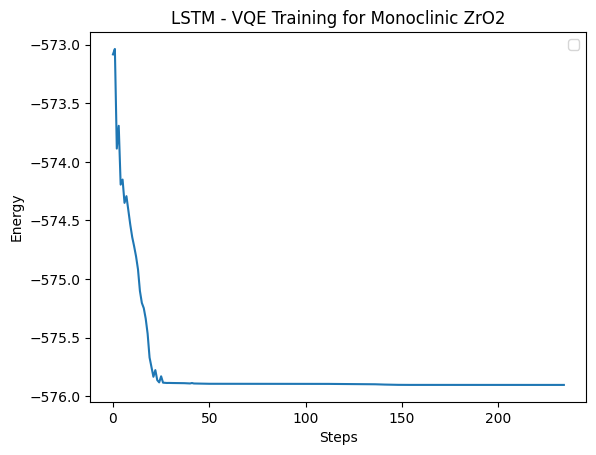

Estimated ground state energy of Monoclinic ZrO2: -575.9043055121782


In [21]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [51]:
-575.9406119198592

-575.9406119198592

In [61]:
print('L5_bfgs=',energy_list)

L5_bfgs= [-572.2724015243889, -573.7876415335445, -573.1644606050901, -574.0659970244501, -574.1963622269432, -574.4347143447542, -574.7468646691884, -574.7327424970747, -574.9173642996279, -575.177989592796, -575.1112798857687, -575.3378167288174, -575.4512851772113, -575.6338160011962, -575.861000462267, -575.2607532290996, -575.9118073389803, -575.8652675198094, -575.930133428217, -575.932098334253, -575.9349363863877, -575.937921203702, -575.9365010453857, -575.938372004483, -575.9383766481004, -575.9384503717886, -575.938458962312, -575.9384648918282, -575.9384702661483, -575.9384794463601, -575.938493589626, -575.9385033632417, -575.93850557039, -575.9385061904521, -575.9385064809616, -575.9385065985462, -575.9385066279724, -575.9385066352658, -575.938506637206, -575.9385066374713]


## 优化 L-BFGS-B

In [22]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [23]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [28]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [29]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [30]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='L-BFGS-B', jac=True)

Step: 5,	energy: -574.1978581077854
Step: 10,	energy: -574.6370869762534
Step: 15,	energy: -575.5171237244244
Step: 20,	energy: -575.9042938068944
Step: 25,	energy: -575.9372242170474
Step: 30,	energy: -575.9383926120292
Step: 35,	energy: -575.9384913228499


/tmp/ipykernel_1083064/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


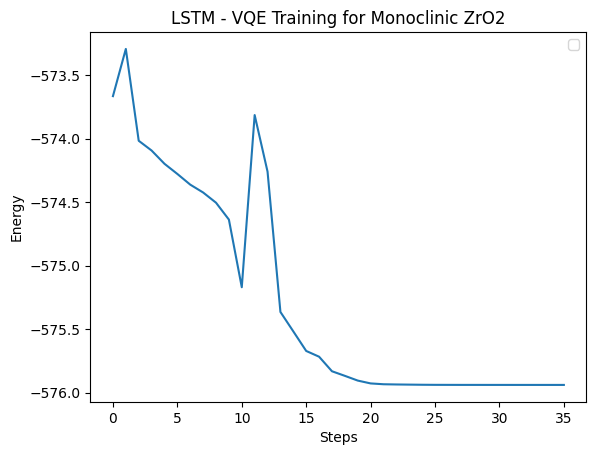

Estimated ground state energy of Monoclinic ZrO2: -575.9384923982342


In [31]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [32]:
-575.9384923982342

-575.9384923982342

In [33]:
print('L5_L_BFGS_B=',energy_list)

L5_L_BFGS_B= [-573.6654124610416, -573.2937341707359, -574.0165493339048, -574.0935454686664, -574.1978581077854, -574.2779177732382, -574.3619995471164, -574.4238798107489, -574.5041416858817, -574.6370869762534, -575.1695869135294, -573.8143914639703, -574.259744954614, -575.3642119138669, -575.5171237244244, -575.67113687627, -575.7164072423437, -575.8309260448702, -575.8670085993226, -575.9042938068944, -575.926715061763, -575.9331881608791, -575.9349357322794, -575.9361168373371, -575.9372242170474, -575.9378979257748, -575.9380913734853, -575.9382901657915, -575.9383120045471, -575.9383926120292, -575.9384209504203, -575.9384642734361, -575.9384800971386, -575.9384882519653, -575.9384913228499, -575.9384923982342]


## 优化 CG

In [36]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [55]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [56]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [57]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='CG', jac=True,options={'maxiter': 200})

Step: 5,	energy: -574.2682730914386
Step: 10,	energy: -574.977830333767
Step: 15,	energy: -575.7312542529978
Step: 20,	energy: -575.923613886976
Step: 25,	energy: -575.9350270109178
Step: 30,	energy: -575.936932873498
Step: 35,	energy: -575.9376980187318
Step: 40,	energy: -575.9381046327441
Step: 45,	energy: -575.9380042408342
Step: 50,	energy: -575.9382995681439
Step: 55,	energy: -575.9384096970605
Step: 60,	energy: -575.9384500445412
Step: 65,	energy: -575.9384639695373
Step: 70,	energy: -575.9384813113911
Step: 75,	energy: -575.9384924484211
Step: 80,	energy: -575.9384993905338
Step: 85,	energy: -575.9385021594818
Step: 90,	energy: -575.9385039723678
Step: 95,	energy: -575.9385035903982
Step: 100,	energy: -575.9385046255671
Step: 105,	energy: -575.9385054852482
Step: 110,	energy: -575.9385071060723
Step: 115,	energy: -575.9385080510671
Step: 120,	energy: -575.9385083018317
Step: 125,	energy: -575.9385083716697
Step: 130,	energy: -575.9385085298695
Step: 135,	energy: -575.93850859765

/tmp/ipykernel_1083064/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


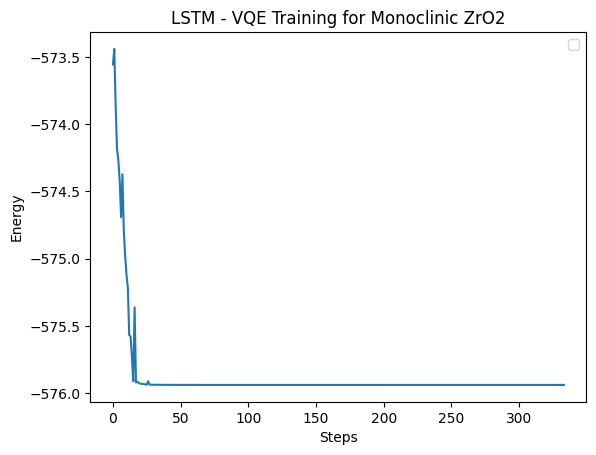

Estimated ground state energy of Monoclinic ZrO2: -575.9385277508226


In [58]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [50]:
-575.9393940257365

-575.9393940257365

In [59]:
print('L5_CG=',energy_list)

L5_CG= [-573.5551760381616, -573.4397188358159, -573.8666264656323, -574.1828853872667, -574.2682730914386, -574.4226308917697, -574.6907836019128, -574.3715439609725, -574.7896382023096, -574.977830333767, -575.1171632840803, -575.2169695436216, -575.5676833168466, -575.5776235332517, -575.7312542529978, -575.9110962090726, -575.361871109721, -575.9200251619314, -575.9153239614619, -575.923613886976, -575.9277856945345, -575.9308900001714, -575.9311956515457, -575.9325026004148, -575.9350270109178, -575.9361239418264, -575.9108080113125, -575.9365345289083, -575.9367867005091, -575.936932873498, -575.9369653089987, -575.9372703582425, -575.9375498428187, -575.9363836284729, -575.9376980187318, -575.9378491348557, -575.9378625296068, -575.9379289244007, -575.9380345073521, -575.9381046327441, -575.9378297628342, -575.9381166341386, -575.9381386849263, -575.9381831020696, -575.9380042408342, -575.9381974722294, -575.9382193672843, -575.9382270411952, -575.9382546606122, -575.93829956814

## 优化 SLSQP

In [80]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [81]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='SLSQP', jac=True)

Step: 5,	energy: -574.7338554721834
Step: 10,	energy: -574.7316773503677
Step: 15,	energy: -575.9133112685851
Step: 20,	energy: -575.9331553361924
Step: 25,	energy: -575.9379549367713
Step: 30,	energy: -575.9384710372949


/tmp/ipykernel_1083064/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


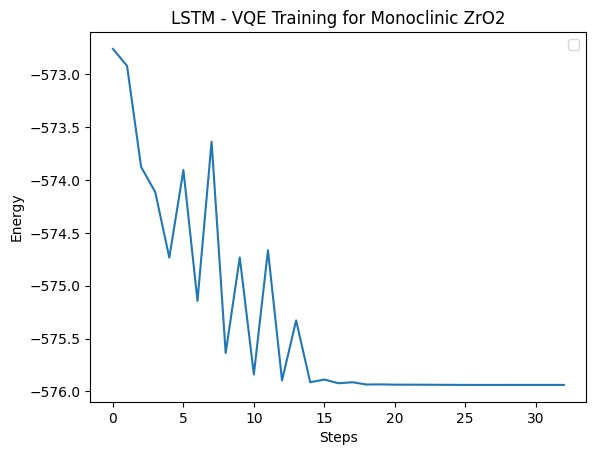

Estimated ground state energy of Monoclinic ZrO2: -575.9384789596421


In [82]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [66]:
-575.9385207804754

-575.9385207804754

In [83]:
print('L5_SLSQP=',energy_list)

L5_SLSQP= [-572.7585128301073, -572.9188242340863, -573.8762463492283, -574.112340713849, -574.7338554721834, -573.9054650843293, -575.1431211242027, -573.6361921641344, -575.6367652255316, -574.7316773503677, -575.8395481003578, -574.6641863062962, -575.8960330869769, -575.3279167861106, -575.9133112685851, -575.8875156666402, -575.9226055215565, -575.9131725416224, -575.9348991204118, -575.9331553361924, -575.9359976133406, -575.9361815812867, -575.9366171686149, -575.9370715670149, -575.9379549367713, -575.9383074153881, -575.9384196278762, -575.9384442921754, -575.9384606001712, -575.9384710372949, -575.9384763047719, -575.9384781313821, -575.9384789596421]
